In [16]:
#1. Prepare Data for Analysis
    #Begin by importing necessary libraries

import pandas as pd

import numpy as np

import matplotlib.pyplot as plt

%matplotlib inline

from sklearn.preprocessing import MinMaxScaler

In [17]:
# Read the csv file and store it as a DataFrame named df

df = pd.read_csv('Documents/class material/data analytics with python/project1/Sales.csv')
print(df)

           Date        Time State     Group  Unit  Sales
0     01-Oct-20     Morning    WA      Kids     8  20000
1     01-Oct-20     Morning    WA       Men     8  20000
2     01-Oct-20     Morning    WA     Women     4  10000
3     01-Oct-20     Morning    WA   Seniors    15  37500
4     01-Oct-20   Afternoon    WA      Kids     3   7500
...         ...         ...   ...       ...   ...    ...
7555  30-Dec-20   Afternoon    TX   Seniors    14  35000
7556  30-Dec-20     Evening    TX      Kids    15  37500
7557  30-Dec-20     Evening    TX       Men    15  37500
7558  30-Dec-20     Evening    TX     Women    11  27500
7559  30-Dec-20     Evening    TX   Seniors    13  32500

[7560 rows x 6 columns]


In [18]:
#Print the DataFrame df and determine its dimensions
df.shape


(7560, 6)

In [19]:
#Display information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7560 entries, 0 to 7559
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Date    7560 non-null   object
 1   Time    7560 non-null   object
 2   State   7560 non-null   object
 3   Group   7560 non-null   object
 4   Unit    7560 non-null   int64 
 5   Sales   7560 non-null   int64 
dtypes: int64(2), object(4)
memory usage: 354.5+ KB


In [20]:
#Check for missing values in the DataFrame
df.isnull().sum()

Date     0
Time     0
State    0
Group    0
Unit     0
Sales    0
dtype: int64

In [21]:
#2. Normalize Data for Analysis
  #• Create a new DataFrame called df_dataonly from the existing df object

df_dataonly = df[['Unit','Sales']]

In [22]:
#Normalize the data

scaler = MinMaxScaler()
normalize_data = scaler.fit_transform(df_dataonly)
normalize_data

array([[0.0952381 , 0.0952381 ],
       [0.0952381 , 0.0952381 ],
       [0.03174603, 0.03174603],
       ...,
       [0.20634921, 0.20634921],
       [0.14285714, 0.14285714],
       [0.17460317, 0.17460317]])

In [23]:
#Check minimum and maximum
normalize_data.min(axis=0)


array([0., 0.])

In [24]:
normalize_data.max(axis=0)

array([1., 1.])

/var/folders/rv/pr7j2l2j68vf75rk_l_sxlgw0000gn/T/ipykernel_1167/959186856.py:4: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Date'] = pd.to_datetime(df['Date'])


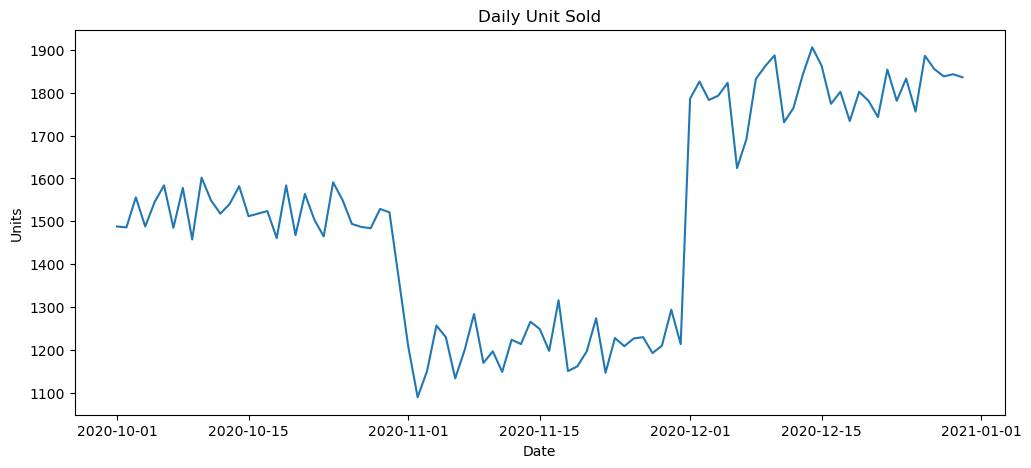

In [25]:
#3. Visualize Overall Trends
# Plot the Date versus Unit and Date versus Sales line plot for the entire season. Note the values of Unit and Sales are summed upfor each day

df['Date'] = pd.to_datetime(df['Date'])
daily = df.groupby("Date").sum(numeric_only =True)

plt.figure(figsize =(12,5))
plt.plot(daily.index,daily['Unit'])
plt.title('Daily Unit Sold')
plt.xlabel("Date")
plt.ylabel("Units")
plt.show()


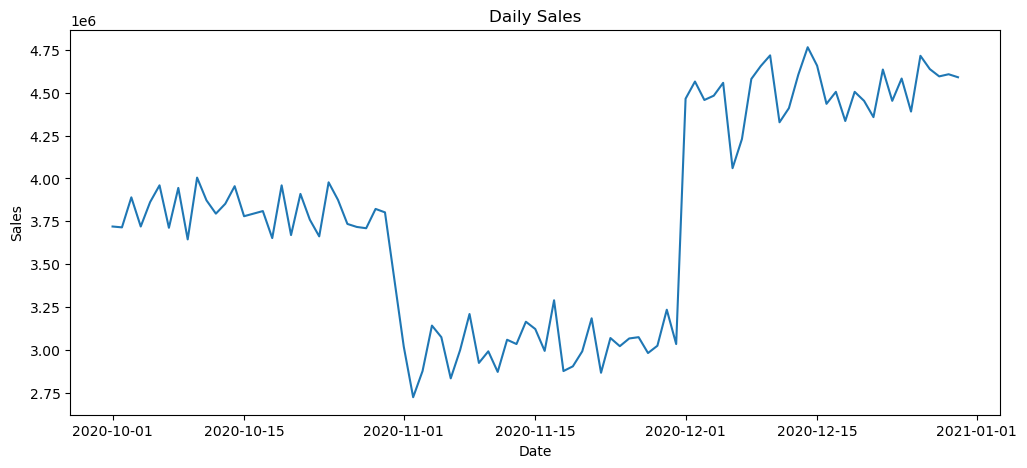

In [26]:
plt.figure(figsize=(12,5))

plt.plot(daily.index, daily['Sales'])

plt.title("Daily Sales")

plt.xlabel("Date")

plt.ylabel("Sales")

plt.show()

In [27]:
#4. Analyze Monthly Data
#• Chunk this quarterly data into monthly data and perform the analysis. For each month, get the sub-DataFrame, using the loc
#feature of DataFrame, and pass the range by date.

df = df.set_index("Date")
df_oct = df.loc["2020-10"]
df_nov = df.loc["2020-11"]
df_dec = df.loc["2020-12"]

In [28]:
#5. Describe Data
#• Describing the data will give you basic information such as count,mean, std (standard deviation), min, max and the quartiles. You will
#use the describe() command on the DataFrame to get it. All the values are for the entire three-month period.

df.describe()

,Unit,Sales
count,7560.000000,7560.000000
mean,18.005423,45013.558201
std,12.901403,32253.506944
min,2.000000,5000.000000
25%,8.000000,20000.000000
50%,14.000000,35000.000000
75%,26.000000,65000.000000
max,65.000000,162500.000000


In [29]:
df_oct.describe()

,Unit,Sales
count,2520.000000,2520.000000
mean,18.141270,45353.174603
std,11.944521,29861.302213
min,3.000000,7500.000000
25%,9.000000,22500.000000
50%,14.000000,35000.000000
75%,27.000000,67500.000000
max,50.000000,125000.000000


In [30]:
df_nov.describe()

,Unit,Sales
count,2520.000000,2520.000000
mean,14.394048,35985.119048
std,10.946470,27366.175823
min,2.000000,5000.000000
25%,6.000000,15000.000000
50%,10.000000,25000.000000
75%,22.000000,55000.000000
max,45.000000,112500.000000


In [31]:
df_dec.describe()

,Unit,Sales
count,2520.000000,2520.000000
mean,21.480952,53702.380952
std,14.554181,36385.451298
min,5.000000,12500.000000
25%,10.000000,25000.000000
50%,15.000000,37500.000000
75%,31.000000,77500.000000
max,65.000000,162500.000000


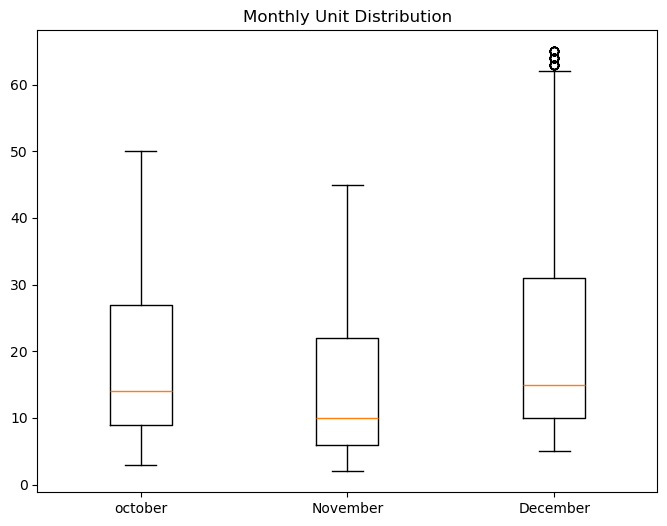

In [35]:
#6. Analyze Unit Data
  #• Unit Analysis
     # ▪ You will use boxplots to visualize the distribution of
units sold for each month.
plt.figure(figsize=(8,6))
plt.boxplot([
    df_oct["Unit"],
    df_nov["Unit"],
    df_dec["Unit"]
])

plt.xticks([1,2,3],["october","November","December"])
plt.title("Monthly Unit Distribution")
plt.show()

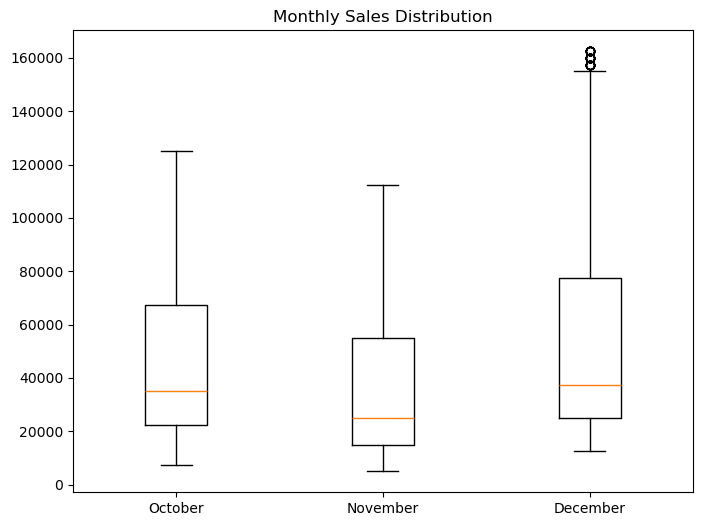

In [36]:
# Sales Analysis
   # You will explore the distribution of sales revenue for each month.

plt.figure(figsize=(8,6))

plt.boxplot([
    df_oct["Sales"],
    df_nov["Sales"],
    df_dec["Sales"]
    
])

plt.xticks([1,2,3],["October","November","December"])
plt.title("Monthly Sales Distribution")

plt.show()

In [37]:
#7. Explore Monthly Plots and Analysis Overall Unit and Sales figures
total_units =df["Unit"].sum()
total_sales =df["Sales"].sum()

print("Total Units:", total_units)
print("Total Sales:", total_sales)



Total Units: 136121
Total Sales: 340302500


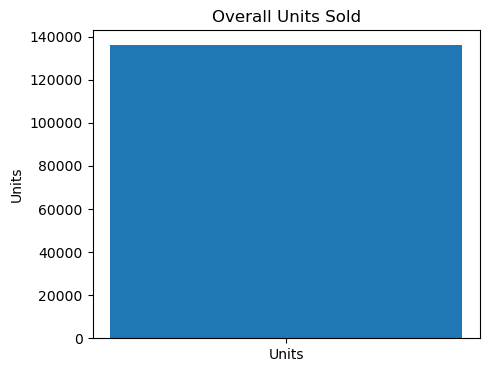

In [46]:

#Interpretation of Overall Units and Sales Figures
     #The Overall Units and Sales chart provides a summary of the company's performance during the three-month period. 
     #It shows the total number of units sold and the total sales generated across all transactions. 
     #This visualization enables management to quickly assess the overall business performance without examining individual records. 
     #A higher total sales value indicates strong revenue generation, while the total units sold reflect the overall demand for 
     #the company's products during the quarter.

plt.figure(figsize=(5,4))

plt.bar(["Units"], [total_units])

plt.title("Overall Units Sold")
plt.ylabel("Units")

plt.show()

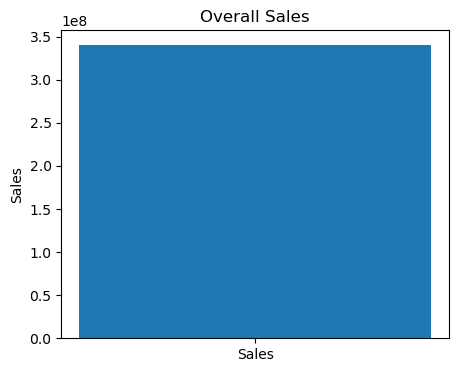

In [47]:
plt.figure(figsize=(5,4))

plt.bar(["Sales"], [total_sales])

plt.title("Overall Sales")
plt.ylabel("Sales")

plt.show()

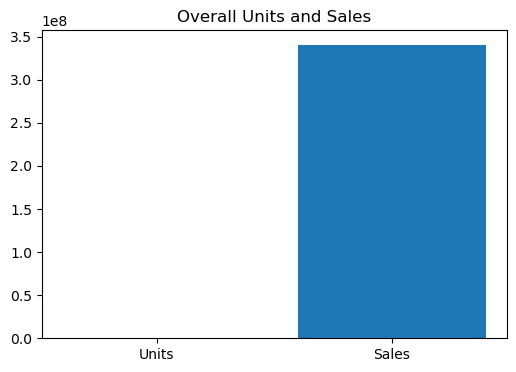

In [49]:
total_units = df["Unit"].sum()
total_sales = df["Sales"].sum()

plt.figure(figsize=(6,4))
plt.bar(["Units", "Sales"], [total_units, total_sales])

plt.title("Overall Units and Sales")
plt.show()


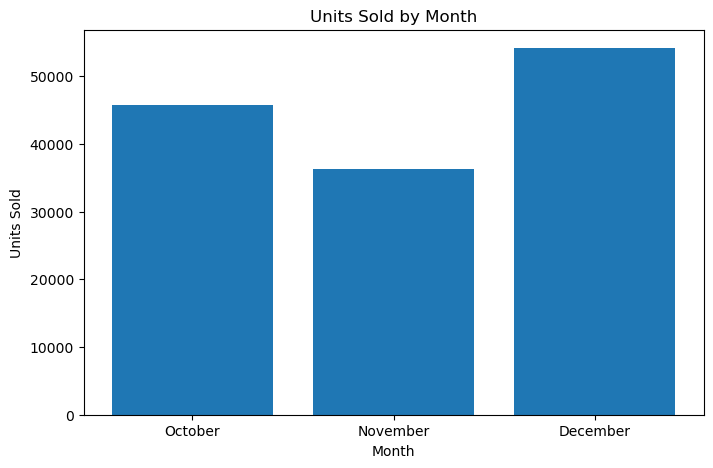

In [41]:
#• Units sold in October, November, and December

#Interpretation of Units Sold in October, November, and December
   #The chart shows that December recorded the highest number of units sold, followed by October, while November had the lowest unit sales.
   #This indicates that customer demand increased significantly toward the end of the quarter,suggesting stronger sales performance in 
   #December and providing valuable insights for future inventory planning and business decision-making.


oct_units =df_oct["Unit"].sum()
nov_units =df_nov["Unit"].sum()
dec_units =df_dec["Unit"].sum()

plt.figure(figsize=(8,5))

plt.bar(
    ["October","November","December"],
    [oct_units, nov_units, dec_units]
)

plt.title("Units Sold by Month")
plt.xlabel("Month")
plt.ylabel("Units Sold")

plt.show()

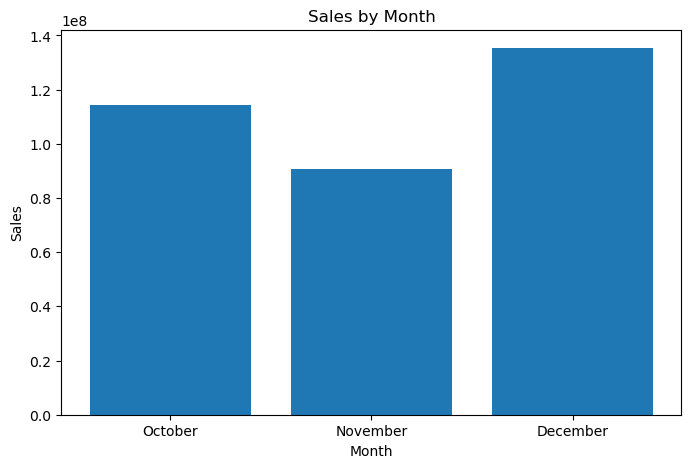

In [42]:
#• Sales numbers for October, November, and December
  #Interpretation
        #The chart shows that December generated the highest sales revenue, followed by October, while November recorded the lowest sales.
        #This indicates that the company's revenue improved significantly toward the end of the quarter, 
        #suggesting stronger customer purchasing activity in December. These results can help management identify seasonal sales trends and 
        #support future planning, budgeting, and marketing strategies.

oct_sales =df_oct["Sales"].sum()
nov_sales =df_nov["Sales"].sum()
dec_sales =df_dec["Sales"].sum()

plt.figure(figsize=(8,5))

plt.bar(
    ["October","November","December"],
    [oct_sales, nov_sales, dec_sales]
    
)
plt.title("Sales by Month")
plt.xlabel("Month")
plt.ylabel("Sales")

plt.show()

<Figure size 1200x500 with 0 Axes>

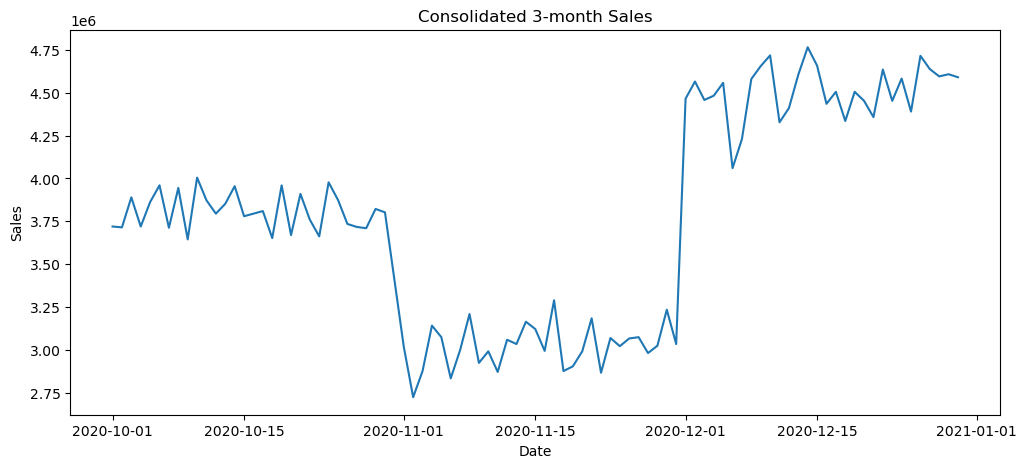

In [44]:
#• Consolidated 3-month sales plot
daily_sales =df.groupby(df.index)["Sales"].sum()

plt.figure(figsize=(12,5))

plt.plot(daily_sales.index,daily_sales.values)

plt.title("Consolidated 3-month Sales")
plt.xlabel("Date")
plt.ylabel("Sales")

plt.show()





In [45]:
# Consolidated Three-Month Sales Trend Analysis
   #-The consolidated 3-month sales plot displays the total sales for each day from October to December. 
    #It helps visualize how sales changed over time, making it easier to identify increases, decreases, and
     #. unusual peaks in sales activity. By summarizing all daily transactions into one value per day, 
      #the graph provides a clear picture of the company's overall sales performance during the quarter.

In [53]:
# a Comprehensive Snapshot
print("COMPREHENSIVE SNAPSHOT")
print("----------------------")

print("Total Units Sold :", df["Unit"].sum())
print("Total Sales      :", df["Sales"].sum())
print("Average Units    :", df["Unit"].mean())
print("Average Sales    :", df["Sales"].mean())
print("Highest Sales    :", df["Sales"].max())
print("Lowest Sales     :", df["Sales"].min())

COMPREHENSIVE SNAPSHOT
----------------------
Total Units Sold : 136121
Total Sales      : 340302500
Average Units    : 18.00542328042328
Average Sales    : 45013.5582010582
Highest Sales    : 162500
Lowest Sales     : 5000


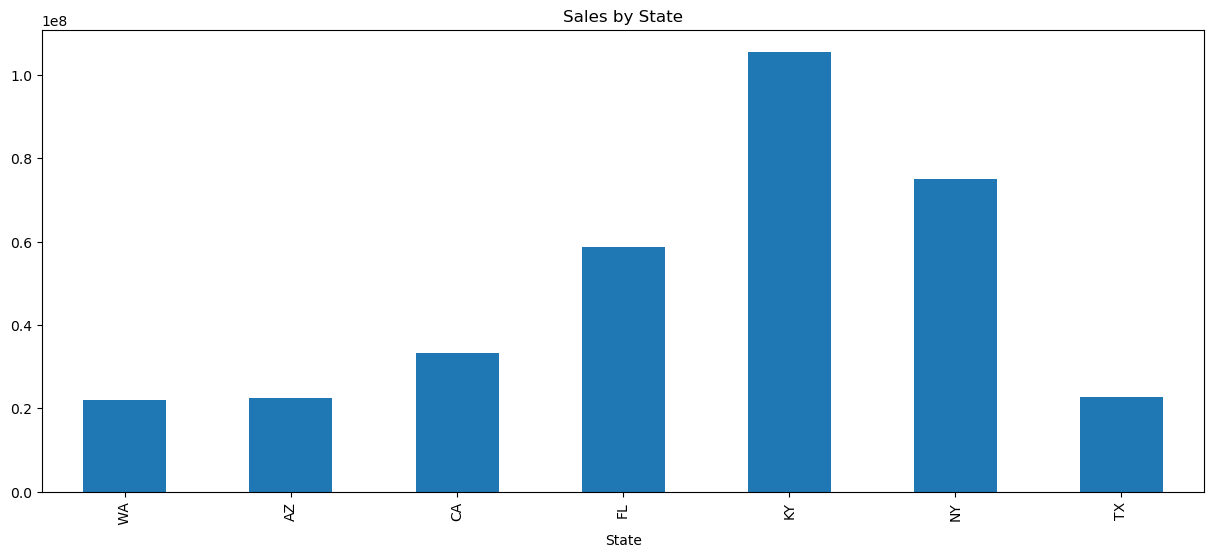

In [64]:
#9. Analyze Statewise Sales in the United States
state_sales =df.groupby("State")["Sales"].sum()

state_sales.plot(kind="bar", figsize=(15,6))

plt.title("Sales by State")
  
plt.show()


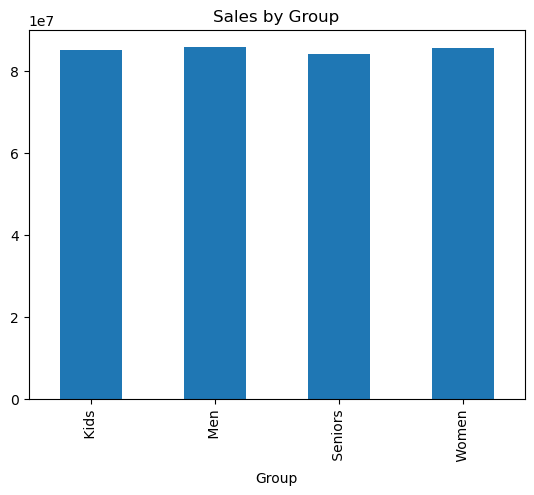

In [65]:
#10. Conduct Groupwise Analysis

group_sales = df.groupby("Group")["Sales"].sum()

group_sales.plot(kind="bar")

plt.title("Sales by Group")

plt.show()

/var/folders/rv/pr7j2l2j68vf75rk_l_sxlgw0000gn/T/ipykernel_1167/2093590307.py:3: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly = df.resample("M").sum(numeric_only=True)


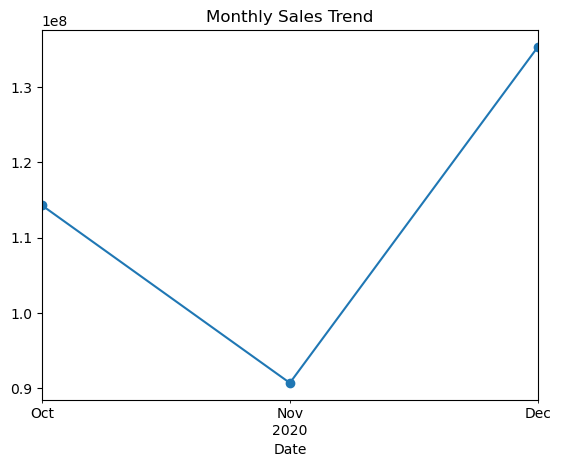

In [66]:
#11. Explore Timewise Analysis

monthly = df.resample("M").sum(numeric_only=True)

monthly["Sales"].plot(marker="o")

plt.title("Monthly Sales Trend")

plt.show()